<a href="https://colab.research.google.com/github/JMBONGO/analyse-couts-transport-/blob/main/Analyse_quantitative_des_couts_de_transport.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:


# PROJET : Analyse quantitative des coûts de transport
# Données synthétiques - aucune donnée réelle de SOCOSI

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Pour reproduire les mêmes résultats
np.random.seed(42)

print("Bibliothèques chargées avec succès.")

Bibliothèques chargées avec succès.


In [ ]:


# Paramètres de la simulation
n_vehicules = 20
n_interventions = 1200

vehicules = [f"CAMION_{i:02d}" for i in range(1, n_vehicules + 1)]

# Véhicules affectés aux interventions
vehicule = np.random.choice(vehicules, n_interventions)

# Distances parcourues par intervention
distance_km = np.random.gamma(
    shape=3, scale=35, size=n_interventions
)
distance_km = np.maximum(distance_km, 10).round(1)

# Consommation moyenne : litres pour 100 km
consommation_100km = np.random.normal(
    28, 4, n_interventions
).clip(18, 45)

# Prix fictif du carburant en FCFA/litre
prix_litre = np.random.normal(
    625, 15, n_interventions
).clip(580, 680)

# Coût de carburant par intervention
litres = distance_km * consommation_100km / 100
cout_carburant = litres * prix_litre

# Autres coûts de l'intervention
cout_maintenance = np.random.gamma(
    shape=2, scale=12000, size=n_interventions
)
cout_autres = np.random.uniform(
    5000, 30000, n_interventions
)

# Dates réparties sur six mois
dates = pd.date_range(
    start="2026-04-01", periods=180, freq="D"
)
date_intervention = np.random.choice(dates, n_interventions)

# Construction du tableau
df = pd.DataFrame({
    "date": date_intervention,
    "vehicule": vehicule,
    "distance_km": distance_km,
    "consommation_100km": consommation_100km.round(2),
    "litres": litres.round(2),
    "prix_litre": prix_litre.round(2),
    "cout_carburant": cout_carburant.round(0),
    "cout_maintenance": cout_maintenance.round(0),
    "cout_autres": cout_autres.round(0)
})

df["cout_total"] = (
    df["cout_carburant"]
    + df["cout_maintenance"]
    + df["cout_autres"]
)

df = df.sort_values("date").reset_index(drop=True)

print("Nombre d'interventions :", len(df))
display(df.head(10))

Nombre d'interventions : 1200


,date,vehicule,distance_km,consommation_100km,litres,prix_litre,cout_carburant,cout_maintenance,cout_autres,cout_total
0,2026-04-01,CAMION_15,277.0,25.39,70.33,629.29,44256.0,25479.0,18100.0,87835.0
1,2026-04-01,CAMION_03,212.7,37.18,79.08,621.43,49142.0,13216.0,6049.0,68407.0
2,2026-04-01,CAMION_20,27.5,30.24,8.32,634.93,5280.0,55407.0,10673.0,71360.0
3,2026-04-02,CAMION_02,66.0,24.94,16.46,619.97,10204.0,9788.0,28259.0,48251.0
4,2026-04-02,CAMION_14,42.2,23.08,9.74,620.96,6048.0,8557.0,28986.0,43591.0
5,2026-04-02,CAMION_13,34.0,28.49,9.69,617.19,5978.0,19946.0,28812.0,54736.0
6,2026-04-02,CAMION_03,317.0,28.88,91.54,633.95,58031.0,41890.0,21963.0,121884.0
7,2026-04-02,CAMION_06,30.5,33.82,10.32,657.18,6779.0,5621.0,22802.0,35202.0
8,2026-04-02,CAMION_18,125.8,24.69,31.06,620.90,19282.0,5614.0,10565.0,35461.0
9,2026-04-03,CAMION_11,113.8,21.97,25.00,612.84,15320.0,2140.0,21974.0,39434.0


In [ ]:


# Éviter les divisions par zéro
df["cout_km"] = df["cout_total"] / df["distance_km"]

df["cout_carburant_km"] = (
    df["cout_carburant"] / df["distance_km"]
)

df["consommation_reelle_100km"] = (
    df["litres"] / df["distance_km"] * 100
)

indicateurs = pd.Series({
    "Nombre d'interventions": len(df),
    "Distance totale (km)": df["distance_km"].sum(),
    "Dépenses totales (FCFA)": df["cout_total"].sum(),
    "Coût moyen par intervention (FCFA)": df["cout_total"].mean(),
    "Coût moyen par km (FCFA)": df["cout_total"].sum()
        / df["distance_km"].sum(),
    "Consommation moyenne (L/100 km)": df["litres"].sum()
        / df["distance_km"].sum() * 100
})

display(indicateurs.round(2).to_frame("Valeur"))

,Valeur
Nombre d'interventions,1200.00
Distance totale (km),123631.50
Dépenses totales (FCFA),71228277.00
Coût moyen par intervention (FCFA),59356.90
Coût moyen par km (FCFA),576.13
Consommation moyenne (L/100 km),28.10


In [ ]:


performance = (
    df.groupby("vehicule")
    .agg(
        interventions=("vehicule", "size"),
        distance_totale=("distance_km", "sum"),
        cout_total=("cout_total", "sum"),
        cout_carburant=("cout_carburant", "sum"),
        cout_maintenance=("cout_maintenance", "sum")
    )
)

performance["cout_km"] = (
    performance["cout_total"] / performance["distance_totale"]
)

performance["part_maintenance_pct"] = (
    performance["cout_maintenance"]
    / performance["cout_total"] * 100
)

performance = performance.sort_values("cout_km")

display(performance.round(2))

,interventions,distance_totale,cout_total,cout_carburant,cout_maintenance,cout_km,part_maintenance_pct
vehicule,,,,,,,
CAMION_12,59,6672.5,3336272.0,1166538.0,1192332.0,500.00,35.74
CAMION_01,79,8841.1,4602191.0,1547915.0,1808412.0,520.55,39.29
CAMION_04,60,6473.5,3404425.0,1141727.0,1203361.0,525.90,35.35
CAMION_13,56,6018.3,3291697.0,1042206.0,1231417.0,546.95,37.41
CAMION_08,69,6610.9,3705274.0,1148543.0,1343300.0,560.48,36.25
CAMION_16,48,5257.4,2961179.0,908263.0,1195076.0,563.24,40.36
CAMION_07,55,5393.6,3059409.0,964961.0,1203755.0,567.23,39.35
CAMION_14,50,5302.7,3011192.0,948156.0,1145457.0,567.86,38.04
CAMION_19,70,7261.1,4182831.0,1305787.0,1699909.0,576.06,40.64


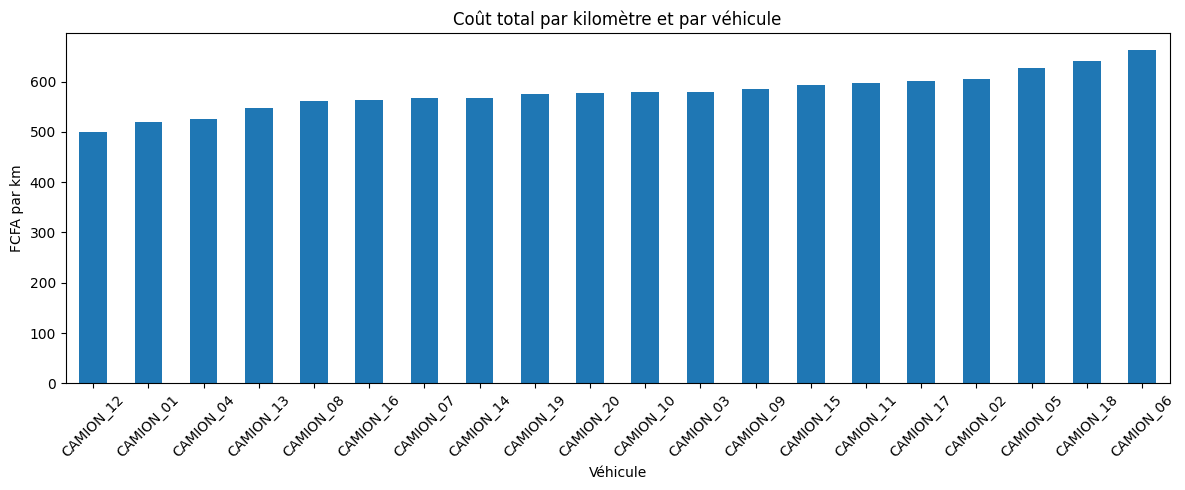

In [ ]:


performance["cout_km"].sort_values().plot(
    kind="bar", figsize=(12, 5)
)

plt.title("Coût total par kilomètre et par véhicule")
plt.xlabel("Véhicule")
plt.ylabel("FCFA par km")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:


# Classement des 5 véhicules les plus coûteux
colonnes = [
    "interventions",
    "distance_totale",
    "cout_km",
    "cout_carburant",
    "cout_maintenance",
    "part_maintenance_pct"
]

print("5 véhicules avec le coût/km le plus élevé :")
display(
    performance.sort_values("cout_km", ascending=False)
    [colonnes]
    .head(5)
    .round(2)
)

5 véhicules avec le coût/km le plus élevé :


,interventions,distance_totale,cout_km,cout_carburant,cout_maintenance,part_maintenance_pct
vehicule,,,,,,
CAMION_06,56,4973.5,663.69,847420.0,1413809.0,42.83
CAMION_18,47,4626.8,641.67,840013.0,1340572.0,45.15
CAMION_05,73,7109.8,626.51,1254787.0,1847953.0,41.49
CAMION_02,63,6332.3,604.70,1070183.0,1613147.0,42.13
CAMION_17,71,7368.8,600.52,1296103.0,1944636.0,43.95


,FCFA par km
Carburant,175.53
Maintenance,230.60
Autres coûts,170.01


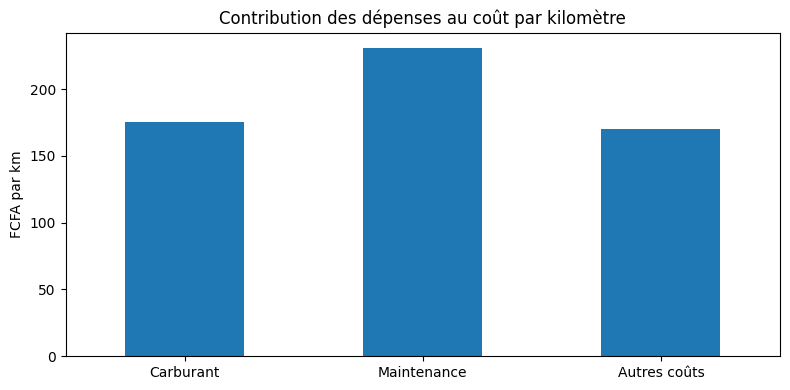

In [ ]:


# Coût moyen au kilomètre par poste de dépense
couts = pd.DataFrame({
    "Carburant": [
        df["cout_carburant"].sum() / df["distance_km"].sum()
    ],
    "Maintenance": [
        df["cout_maintenance"].sum() / df["distance_km"].sum()
    ],
    "Autres coûts": [
        df["cout_autres"].sum() / df["distance_km"].sum()
    ]
}).T

couts.columns = ["FCFA par km"]
display(couts.round(2))

couts.plot(kind="bar", legend=False, figsize=(8, 4))
plt.title("Contribution des dépenses au coût par kilomètre")
plt.ylabel("FCFA par km")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()